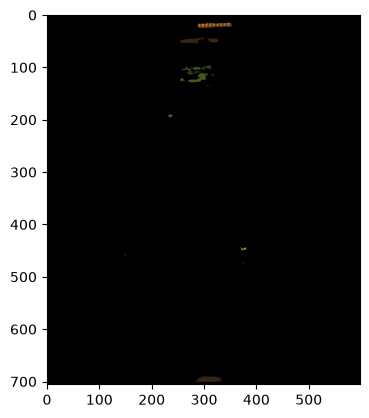

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import math

img = cv.imread("baby_foot_frame.png")                 # BGR
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

# Zones saturées d'une couleur (ex. bleu : H ≈ 100-130)
mask_green = cv.inRange(hsv, (35, 150, 50), (85, 255, 255))
mask_blue  = cv.inRange(hsv, (100, 150, 50), (130, 255, 255))
mask = cv.bitwise_or(mask_green, mask_blue)

#diminuer beaucoup la taille de l'image eavant la detection des bords.

# Zones saturées, toutes couleurs confondues
mask_sat = cv.inRange(hsv, (0, 150, 50), (179, 255, 255))

result = cv.bitwise_and(img, img, mask=mask)

plt.imshow(result)

In [2]:
kernel_close = cv.getStructuringElement(cv.MORPH_RECT, (5, 5))
kernel_open = cv.getStructuringElement(cv.MORPH_RECT, (25, 25))
#proportion du kernbel possiblement a changer en fonction des résultats


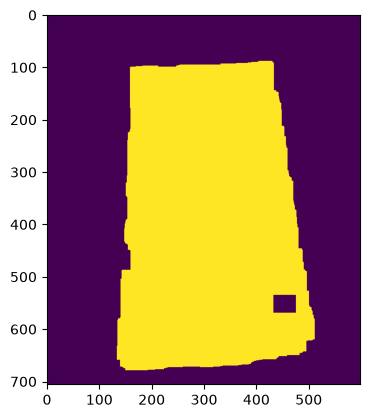

In [3]:
def masked_g_b(param_img):
    hsv = cv.cvtColor(param_img, cv.COLOR_BGR2HSV)
    mask_green = cv.inRange(hsv, (35, 65, 50), (85, 170, 255))
    mask_blue  = cv.inRange(hsv, (100, 150, 50), (130, 255, 255))
    #masque a revoir, surtout pour le vert
    mask = cv.bitwise_or(mask_green, mask_blue)

    opened = cv.morphologyEx(mask_green, cv.MORPH_CLOSE, kernel_close, iterations=8)
    opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_open, iterations=1)
    return opened

plt.imshow(masked_g_b(img))

Recherche des contours par rapport au masque réalisé précédement

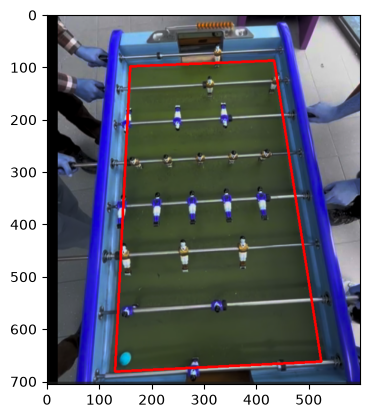

In [4]:
def apply_rectangular_contour(img):
    test_forme = masked_g_b(img)

    contours, _ = cv.findContours(test_forme, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    cnt = contours[0]
    approx = cv.approxPolyN(cv.convexHull(cnt),4,True)

    cv.drawContours(img, approx, -1, (255,0,0), 3)

    return img

img_conto = img.copy()
plt.imshow(apply_rectangular_contour(img_conto))


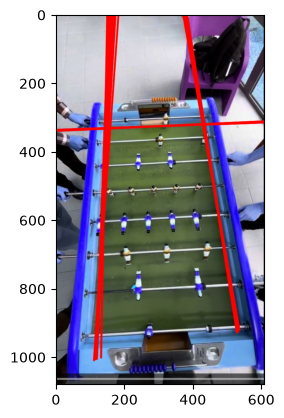

In [10]:
img_conto = img.copy()

test_forme = masked_g_b(img_conto)

edges = cv.Canny(test_forme, 150, 500)
lines = cv.HoughLines(edges, 1, np.pi / 300, 100, None, 0, 0)
lines = cv.HoughLines(edges, 2, np.pi / 360, 150, min_theta=np.pi / 8 , max_theta=np.pi * 7)
lines_hori = cv.HoughLines(edges, 2, np.pi / 180, 100, min_theta=np.pi / 4, max_theta=np.pi / 1.5)
#1 --> alignement des piuxels
#2 grossiérté de l'angle
#3 seuil de la netteté des droites
ens_ligne = []

for rho, theta in lines[:, 0]:
    # display line
    a = math.cos(theta)
    b = math.sin(theta)
    x0 = a * rho
    y0 = b * rho
    pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
    pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
    ens_ligne.append([rho, theta])

    cv.line(img_conto, pt1, pt2, (255,0,0), 3, cv.LINE_AA)
    

plt.imshow(img_conto)

Application des filtres sur la vidéo

In [8]:
vid = cv.VideoCapture("vid_Ryan_Mouvante.mp4")      # chemin de fichier, ou 0 pour la webcam

while True:
    check, frame = vid.read()               # ok = False en fin de vidéo ou en cas d'erreur
    if not check:
        break

    #masked = masked_g_b(frame)
    scale_down = 0.50
    
    frame = cv.resize(frame, None, fx=scale_down, fy=scale_down, interpolation=cv.INTER_LINEAR)
 
    frame = apply_rectangular_contour(frame)

    cv.imshow("expl", frame)
    if cv.waitKey(30) & 0xFF == ord('q'):   # 30 ms ≈ 33 images/s ; 'q' pour quitter
        break

vid.release()
cv.destroyAllWindows()